<a href="https://colab.research.google.com/github/Gene7Ai/Projet_DL_Expressions_faciales/blob/main/TP_1/TP_1_1_AE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical Exercise — Introduction to Deep Generative Models
**Arthur SATOUF**  
## TP 1.1 — Autoencoders on Fashion MNIST


For each practical exercise (TP), please work in groups of two or three. Create a **private GitHub repository** and add **arthur-75**.

> Complete the `xxx` placeholders and answer the questions. Existing starter code and guidance follow the original PDF; example outputs are not provided as solutions.

Use pytorch documentation https://docs.pytorch.org/docs/2.14/index.html to solve.

### Goals
- Load and visualize Fashion MNIST.
- Build a convolutional autoencoder.
- Train and evaluate the model.
- Extract and visualize latent-space embeddings.
- Reconstruct images and generate new ones.

## 1. Load and Visualize the Dataset
### 1.1 Import Necessary Libraries
Before implementation, import the required libraries.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

**Question:** What transformations might be useful when working with images?

*Your answer:* `ToTensor()` to convert the image into a tensor with values between 0 and 1, and `Pad(2)` to go from 28x28 to 32x32, so the size can be divided by 2 three times in the encoder. `Normalize` can also help the training. For the training set we could also use data augmentation like random flips or small rotations.

### 1.2 Prepare the Data
- Load Fashion MNIST (`train=True` for training and `train=False` for validation).
- Pad images from 28 × 28 to 32 × 32.
- Convert images to tensors.
- Use `DataLoader` for mini-batch processing.

In [2]:
# Preprocessing
transform = transforms.Compose([
    transforms.Pad(2),     # Pad 28x28 images to 32x32 (2 pixels on each side)
    transforms.ToTensor(), # Convert images to tensors, values in [0, 1]
])
batch_size = 128

In [3]:
# Load data
train_dataset = datasets.FashionMNIST(root="./data", train=True, transform=transform, download=True)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_dataset = datasets.FashionMNIST(root="./data", train=False, transform=transform, download=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

100%|██████████| 26.4M/26.4M [00:00<00:00, 116MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 4.26MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 59.4MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.72MB/s]


### 1.3 Visualizing Sample Images
- Extract a batch of images and labels.
- Display images in a grid.
- Use Matplotlib to plot grayscale images.

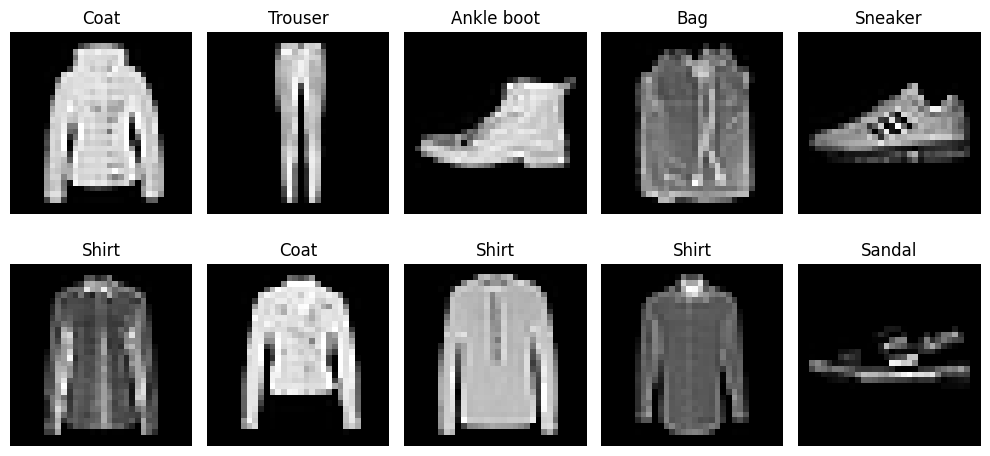

In [4]:
class_labels = {
    0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat',
    5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'
}

def plot_sample_images(loader):
    data_iter = iter(loader)
    images, labels = next(data_iter)
    images = images.numpy()

    plt.figure(figsize=(10, 5))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.title(class_labels[labels[i].item()])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

plot_sample_images(train_loader)

## 2. Build the Autoencoder
An autoencoder consists of:
1. **Encoder:** Reduces an image to a compressed representation (latent space).
2. **Decoder:** Reconstructs the image from its compressed representation.

### 2.1 Define the Autoencoder Model
Use convolutional layers in the encoder and transposed convolutions in the decoder.

### 2.2 Define the Latent Space
Flatten the encoder output, then use a fully connected layer to compress it to **N dimensions**. For this exercise, use **N = 2** for visualization (other applications may use larger dimensions).

**Questions**
- How does reducing dimensionality help the model?
- What happens when the latent space is too small or too large?

*Your answers:*
- The bottleneck forces the model to keep only the important information of the image not every pixel, so it can't just copy the input. It also gives a small vector that we can plot, or decode to make new images.
- If the latent space is too small , we lose a lot of information: the reconstructions are blurry and some classes get mixed. If it is too big, the reconstructions are better but the model can almost copy the input, and the latent space is harder to visualise and to use for generation.

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Define the Autoencoder Model
class Autoencoder(nn.Module):
    def __init__(self, input_shape=(1, 32, 32), latent_dim=2):
        """
        Initialize the Autoencoder model.
        - input_shape: (1, 32, 32) for grayscale images.
        - latent_dim: Number of neurons in the latent space.
        """
        super(Autoencoder, self).__init__()

        # Encoder: 1x32x32 -> 32x16x16 -> 64x8x8 -> 128x4x4
        self.encoder = nn.Sequential(
            # First convolutional layer: 1 channel -> 32 feature maps
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),  # Activation function

            # Second convolutional layer
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),  # Activation function

            # Third convolutional layer
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU()  # Activation function
        )

        # Dynamically calculate the flattened size after encoding
        flattened_size, decode_shape = self.calculate_flattened_size(self.encoder, input_shape)

        # Latent space: 128*4*4 = 2048 -> latent_dim
        self.fc = nn.Sequential(
            nn.Flatten(start_dim=1),  # Flatten encoded features
            nn.Linear(flattened_size, latent_dim)  # Latent dimension
        )

        # Decoder: latent_dim -> 128x4x4 -> 64x8x8 -> 32x16x16 -> 1x32x32
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, flattened_size),  # Latent space -> feature map
            nn.Unflatten(1, decode_shape[1:]),       # (B, 2048) -> (B, 128, 4, 4)

            # Transposed convolution layers
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),  # Activation

            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),  # Activation

            # Final layer: single-channel grayscale output
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()  # Output between 0 and 1
        )

    def calculate_flattened_size(self, model, input_shape):
        """Return the flattened encoder size and output shape."""
        with torch.no_grad():
            dummy_input = torch.zeros(1, *input_shape)
            output = model(dummy_input)
            return output.numel(), output.shape

    def forward(self, x):
        """Return the reconstructed image and latent representation."""
        x = self.encoder(x)  # Encoder
        latent = self.fc(x)
        x = self.decoder(latent)  # Decoder
        return x, latent

### Test dimension consistency

In [6]:
x_sample = torch.randn(1, 1, 32, 32)
model_test = Autoencoder()
image_test, latent_space = model_test(x_sample)
assert image_test.shape == x_sample.shape, "Output dimensions do not match input dimensions!"

## 3. Train the Autoencoder
### 3.1 Define the Training Process
- Choose an optimizer (e.g., Adam, learning rate 0.0001) and a reconstruction loss (e.g., MSE).
- Iterate over epochs and mini-batches.
- Move images to the selected CPU/GPU device.
- Forward pass, compute the loss, backpropagate, and update weights.

### 3.2 Evaluate the Model
- Disable gradients using `torch.no_grad()`.
- Run reconstruction on validation images.
- Calculate validation loss and binary cross-entropy.

In [7]:
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def train_model(model, train_loader, val_loader, epochs):
    """Train the autoencoder."""
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-4)
    loss_fn = nn.MSELoss()

    print("Start Training...")
    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        tqdm_loader = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")

        for x, _ in tqdm_loader:
            x = x.to(device)
            recon_x, _ = model(x)
            # Reconstruction MSE between recon_x and x
            loss = loss_fn(recon_x, x)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            tqdm_loader.set_postfix(loss=loss.item())

        avg_train_loss = total_loss / len(train_loader)
        avg_val_loss, ce_losss = evaluate_model(model, val_loader)
        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        print(f"Epoch [{epoch + 1}/{epochs}], Train Loss: {100*avg_train_loss:.6f} %, "
              f"Val Loss: {100*avg_val_loss:.6f} %, "
              f"Val Loss cross_entropy: {100*ce_losss:.6f} %")

    plot_training_loss(train_losses, val_losses)

In [8]:
def evaluate_model(model, loader):
    """Evaluate the autoencoder on validation data."""
    model.eval()
    total_loss = 0
    loss_fn = nn.MSELoss()  # Same loss function as training
    ce_losss = 0
    with torch.no_grad():
        for x, _ in tqdm(loader, desc="Evaluating"):
            x = x.to(device)
            recon_x, _ = model(x)
            loss = loss_fn(recon_x, x)
            ce_loss = F.binary_cross_entropy(recon_x, x)
            total_loss += loss.item()
            ce_losss += ce_loss.item()

    avg_loss = total_loss / len(loader)
    ce_losss /= len(loader)
    return avg_loss, ce_losss

def plot_training_loss(train_losses, val_losses):
    """Plot the training and validation losses."""
    plt.figure(figsize=(8, 5))
    plt.plot(train_losses, label="Training Loss", marker="o")
    plt.plot(val_losses, label="Validation Loss", marker="s")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid()
    plt.show()

Start Training...


Evaluating: 100%|██████████| 79/79 [00:07<00:00, 11.09it/s]


Epoch [1/10], Train Loss: 6.822564 %, Val Loss: 3.792018 %, Val Loss cross_entropy: 30.764008 %


Evaluating: 100%|██████████| 79/79 [00:05<00:00, 13.60it/s]


Epoch [2/10], Train Loss: 3.429386 %, Val Loss: 3.240500 %, Val Loss cross_entropy: 29.607055 %


Evaluating: 100%|██████████| 79/79 [00:06<00:00, 12.04it/s]


... (11 outputs left out)

Evaluating: 100%|██████████| 79/79 [00:06<00:00, 12.71it/s]


Epoch [9/10], Train Loss: 2.759596 %, Val Loss: 2.742753 %, Val Loss cross_entropy: 27.503240 %


Evaluating: 100%|██████████| 79/79 [00:07<00:00, 10.97it/s]


Epoch [10/10], Train Loss: 2.729241 %, Val Loss: 2.714628 %, Val Loss cross_entropy: 27.359569 %


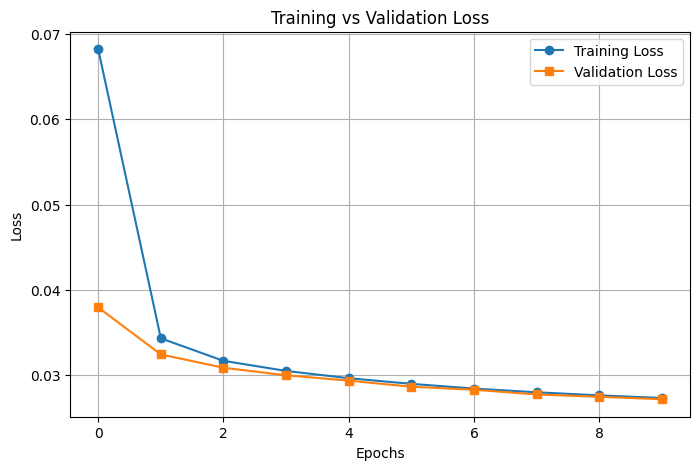

In [9]:
# Instantiate and train the model
autoencoder = Autoencoder()
train_model(autoencoder, train_loader, val_loader, epochs=10)

## 4. Reconstruct Images Using the Autoencoder
### 4.1 Extract a Few Test Images
- Select a validation batch.
- Pass it through the autoencoder and retrieve reconstructions.

### 4.2 Compare Original and Reconstructed Images
- Plot originals on top and reconstructions on the bottom.
- Observe the differences.

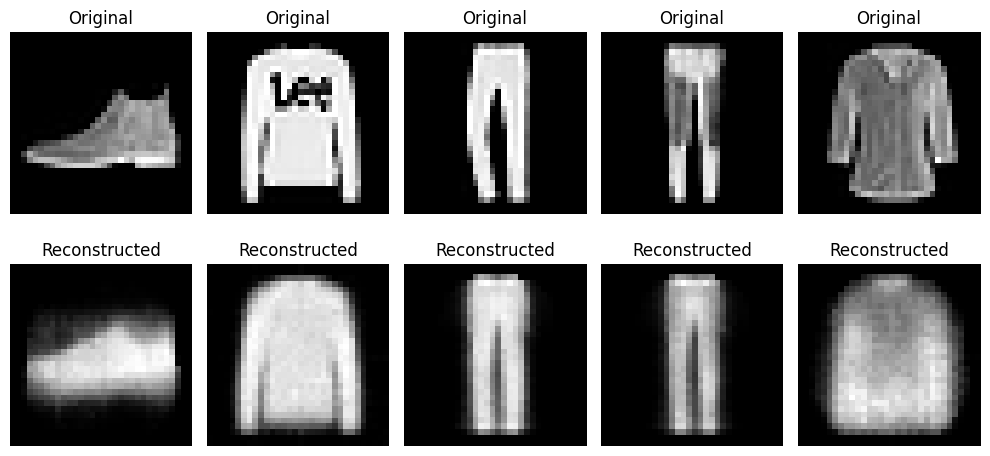

In [10]:
def plot_reconstructions(model, loader, ex=True):
    model.eval()
    model = model.to("cpu")

    with torch.no_grad():
        if ex:
            for x, _ in loader:
                recon_x, _ = model(x)
                break
        else:
            x = loader
            recon_x = model.decoder(x)

    x = x.cpu().numpy()
    recon_x = recon_x.cpu().numpy()

    plt.figure(figsize=(10, 5))
    for i in range(5):
        if ex:
            plt.subplot(2, 5, i + 1)
            plt.imshow(x[i].squeeze(), cmap="gray")
            plt.title("Original")
            plt.axis("off")

        plt.subplot(2, 5, i + 6)
        plt.imshow(recon_x[i].squeeze(), cmap="gray")
        plt.title("Reconstructed")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

plot_reconstructions(autoencoder, val_loader)

**Question:** How could you improve the model to get sharper images?

*Your answer:* Our reconstructions are recognizable but blurry (val MSE around XXX after 10 epochs). The main problem is the latent dimension of 2, it is too small to keep the details. We could use a bigger `latent_dim` (for example 16 or 32), train for more epochs, or add more filters/layers.

## 5. Visualize the Latent Space
### 5.1 Extract Embeddings
- Pass training images through the encoder.
- Store latent representations and labels.

In [11]:
embeddings = []
labels = []

autoencoder = autoencoder.to(device)
autoencoder.eval()
with torch.no_grad():
    for x, y in train_loader:
        x = x.to(device)
        _, latent = autoencoder(x)  # Call the autoencoder and extract embeddings
        embeddings.append(latent.cpu().numpy())
        labels.append(y.numpy())

embeddings = np.concatenate(embeddings, axis=0)
labels = np.concatenate(labels, axis=0)
unique_labels = np.unique(labels)
autoencoder = autoencoder.to("cpu")

### 5.2 Plot in a 2D Space
- For a two-dimensional latent space, plot points in a scatter plot.
- Assign separate colors to the clothing categories.

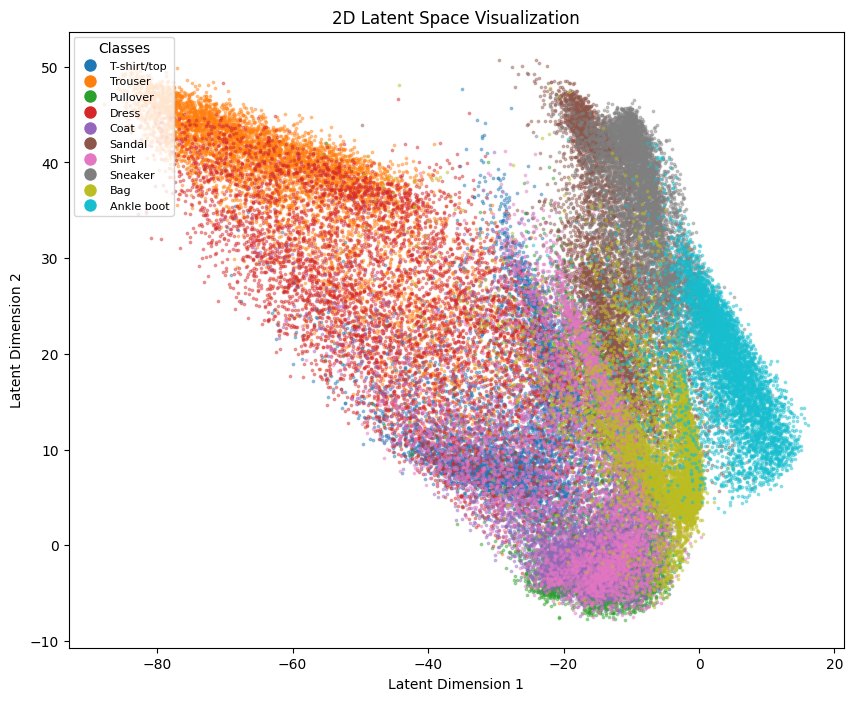

In [12]:
# Plot the 2D embeddings
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

plt.figure(figsize=(10, 8))
legend_handles = []
for i, label in enumerate(unique_labels):
    indices = np.where(labels == label)[0]
    scatter = plt.scatter(
        embeddings[indices, 0], embeddings[indices, 1],
        c=[colors[i]], alpha=0.4, s=3, label=class_labels[label]
    )
    legend_handles.append(
        Line2D([0], [0], marker='o', color='w', label=f'{class_labels[label]}',
               markersize=10, markerfacecolor=colors[i])
    )

plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.title('2D Latent Space Visualization')
plt.legend(handles=legend_handles, title='Classes', loc='upper left', fontsize=8)
plt.show()

**Question:** Would images of similar clothing types cluster together, and are they well represented?

*Your answer:* Yes, in our plot the images of the same class are mostly grouped together, even if the model never used the labels. Trousers, bags and shoes (sandal, sneaker, ankle boot) are quite well separated. But T-shirt, shirt, pullover, coat and dress are mixed together because they have a similar shape, so with only 2 dimensions they are not well represented.

## 6. Generate New Images Using the Decoder
### 6.1 Sample Random Points in Latent Space
- Pick random latent vectors within the range of existing embeddings.
- Pass the vectors through the decoder.

### 6.2 Plot Generated Images
- Display decoder outputs.
- Observe how varying latent vectors changes the generated images.

Generated Latent Samples:
 tensor([[ -6.3704,   0.0785],
        [-37.8160,   2.2967],
        [-34.7130,  -0.3216],
        [-32.5457,  25.0491],
        [-39.3958,  17.2169]])


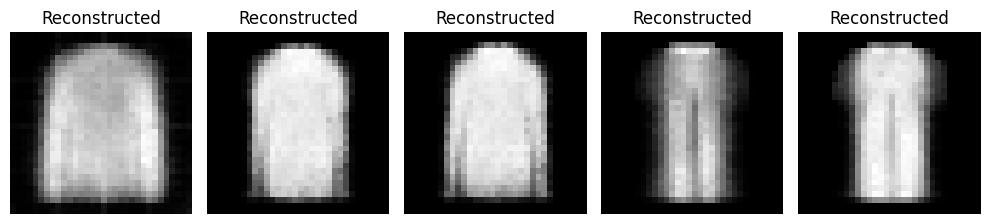

In [13]:
# Generate latent space samples for visualization
mins, maxs = np.min(embeddings, axis=0), np.max(embeddings, axis=0)
sample = torch.tensor(np.random.uniform(mins, maxs, size=(5, 2)), dtype=torch.float32)
print("Generated Latent Samples:\n", sample)
plot_reconstructions(autoencoder, sample, ex=False)

**Question:** Are there any objects not well reconstructed?

*Your answer:* Yes. Some random points fall between two clusters or in empty parts of the latent space, so the image is blurry or looks like a mix of two classes. The classes that overlap (shirt, T-shirt, pullover) also don't give clear images, and small details are lost.

### Example for an ankle boot (provided in the exercise)

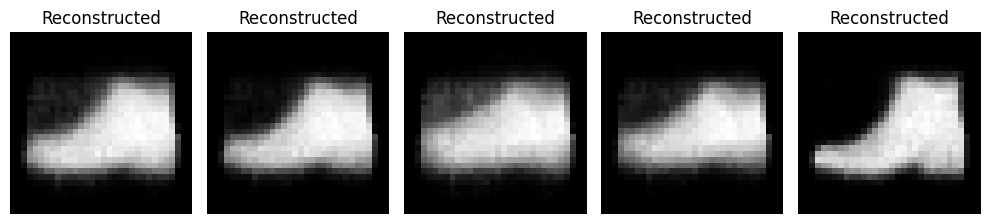

In [14]:
x_sample = torch.tensor([[0., 20], [0., 25], [-2., 20], [-2., 25], [5., 30]])
plot_reconstructions(autoencoder, x_sample, ex=False)

**Task:** Plot examples of **trousers**. (Complete the exercise below.)

Trouser center: [-59.26618  36.47227]


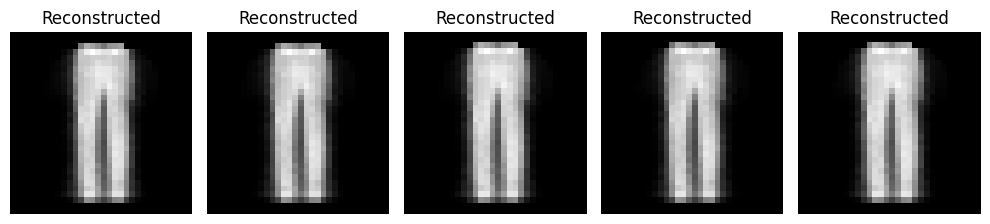

In [15]:
# Plot examples of trousers
# trousers = class 1, we take the mean of their embeddings and move a bit around it
center = embeddings[labels == 1].mean(axis=0)
print("Trouser center:", center)

offsets = np.array([[0, 0], [1, 0], [-1, 0], [0, 1], [0, -1]])
x_sample = torch.tensor(center + offsets, dtype=torch.float32)
plot_reconstructions(autoencoder, x_sample, ex=False)

### Save the model

In [16]:
torch.save(autoencoder.state_dict(), "VAmodel_state_dict.pth")